# Tutorial for Pre-Processing Single-Cell Datasets
**Author:** Wei Yang  
**Region:** lCb Region from multiple sci-RNA-seq3 runs (snRNA-seq QC)  
**Date Last Modified:** October 8, 2023  

---

### Dataset Summary
* **Input:** Unfiltered `.h5ad` file from BAT-Lab pipelines for sci-RNA-seq3 
* **Output:** UMAP QCing putative batch effects from different sci-RNA-seq3 runs

---

### Pipeline Workflow & Quality Control

1. **Initial Quality Filtering**  
   Removed nuclei of low quality or ambient RNA based on the following criteria:
   * **UMI counts:** $< 100$
   * **Genes detected:** $\le 100$
   * **Mitochondrial reads:** $\ge 10\%$
   * **Intronic mapping percentage:** $\ge 20\%$

2. **Doublet Detection (Scrublet)**  
   Subjected the filtered matrix to doublet calling via `Scrublet v0.2.3` (RRID:SCR_018098). Putative doublets were defined as those with scores $> 0.2$.

3. **Cell Type Annotation**  
   Annotated matrix with cell class and cell subtype labels using `TACCO`.

4. **Normalization & Cluster-Based Doublet Removal**  
   Log-normalized the matrix, applied dimensionality reduction, and partitioned via Louvain clustering (`resolution = 6`). Excluded clusters with $> 50\%$ predicted doublets (threshold determined by bimodal distribution).

5. **Outlier Filtering**  
   Excluded remaining low-quality or doublet nuclei with UMI counts $\le \text{mean} - 1\text{ SD}$ or $\ge \text{mean} + 2\text{ SD}$.

6. **Final Processing & Visualization**  
   Re-performed normalization and dimensionality reduction. Visualized final filtered dataset using UMAP (`min_dist = 0.25`, `spread = 1.0`, `n_components = 2`).

In [2]:
import bioalpha
import scanpy as sc
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns
import math
import pandas as pd
import sys
import platform
import subprocess
from time import perf_counter as pc
import statistics
import re

In [3]:
print(f"Python Version: {platform.python_version()}")
print(f"Python Executable: {sys.executable}\n")
print("--- Installed Packages ---")

# Runs pip list using the active kernel's Python executable
result = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True)
print(result.stdout)

Python Version: 3.11.10
Python Executable: /packages/envs/bioalpha-0.13.0-cuda-12/bin/python

--- Installed Packages ---
Package                   Version
------------------------- -----------
anndata                   0.9.2
asttokens                 2.4.1
attrs                     24.2.0
bioalpha-cu12             0.13.1
certifi                   2024.8.30
charset-normalizer        3.4.0
comm                      0.2.2
contourpy                 1.3.0
ctxcore                   0.2.0
cycler                    0.12.1
cytoolz                   1.0.0
debugpy                   1.8.7
decorator                 5.1.1
exceptiongroup            1.2.2
executing                 2.1.0
fastjsonschema            2.20.0
fonttools                 4.54.1
frozendict                2.4.6
GEOparse                  2.0.4
gseapy                    1.1.3
h5py                      3.12.1
idna                      3.10
importlib_metadata        8.5.0
ipykernel                 6.29.5
ipython                   8.2

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
exec(open('/scratch/wyang114/bin/_figure_options.py').read())

In [3]:
np.random.seed(2023)
region = 'control'  #specify region of interest

In [5]:
#open files for region of interest (in kenny's directory after de-multiplexing)
data_dir = f'/scratch/klchiou/bican/hdf5/raw_filtered/anndata_rna_{region}-all.h5ad'
adata = sc.read_h5ad(data_dir)

In [42]:
adata

AnnData object with n_obs × n_vars = 142657 × 10000
    obs: 'sample_id', 'region', 'hemisphere', 'brain_id', 'necropsy_id', 'animal_id', 'sex', 'age', 'social_group', 'sci_library_run_id', 'sequencing_run_id', 'n_umi', 'n_intronic_umi', 'perc_mitochondrial_umis', 'bbi_scrublet_score', 'bbi_scrublet_call', 'scrublet_score', 'scrublet_call', 'sample_reads', 'sample_umi', 'sample_dup_rate', 'sample_doublet_count', 'sample_doublet_perc', 'sample_doublet_nas', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'scrublet_score_from_filtered', 'scrublet_call_from_filtered', '%intronic', 'log2umi', 'louvain', 'scrub_clu'
    var: 'ensembl_gene_id', 'external_gene_name', 'chr', 'bp1', 'bp2', 'strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'louvain', 'umap', 'scrub_clu_colors'
    obsm: 'X_pca', 'X_umap'
    

In [44]:
adata.obs.groupby(['sequencing_run_id','sci_library_run_id']).size().unstack()

sci_library_run_id,Snyder-Mackler_RNA3-051,Snyder-Mackler_RNA3-053_054,Snyder-Mackler_RNA3-056_057,Snyder-Mackler_RNA3-058_059,Snyder-Mackler_RNA3-060_061,Snyder-Mackler_RNA3-062
sequencing_run_id,,,,,,
Snyder-Mackler_RNA3-051.nova_data,28746,0,0,0,0,0
Snyder-Mackler_RNA3-056_057_nova_data,0,0,22191,0,0,0
Snyder-Mackler_RNA3-057_franken_novaseq_data,0,0,3918,0,0,0
Snyder-Mackler_RNA3-058_059_nova_data,0,0,0,12272,0,0
Snyder-Mackler_RNA3-059_franken_novaseq_data,0,0,0,692,0,0
Snyder-Mackler_RNA3-060_061-nova_data,0,0,0,0,22451,0
Snyder-Mackler_RNA3-061_franken_novaseq_data,0,0,0,0,3892,0
Snyder-Mackler_RNA3-062_franken_novaseq_data,0,0,0,0,0,20913
Snyder-Mackler_RNA3_053_054-nova_data,0,27582,0,0,0,0


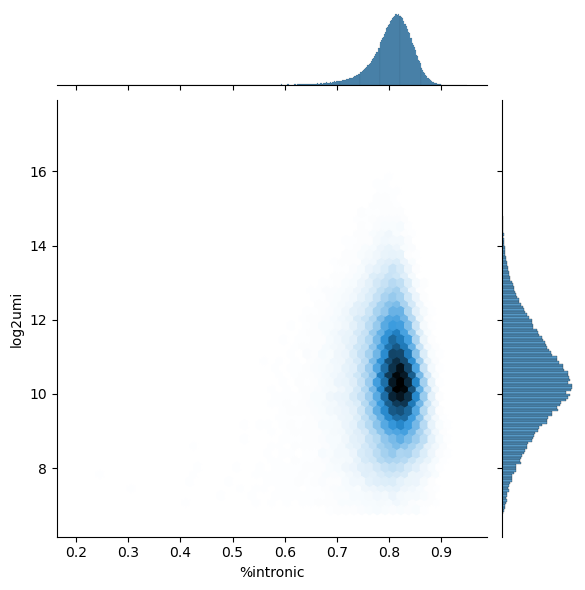

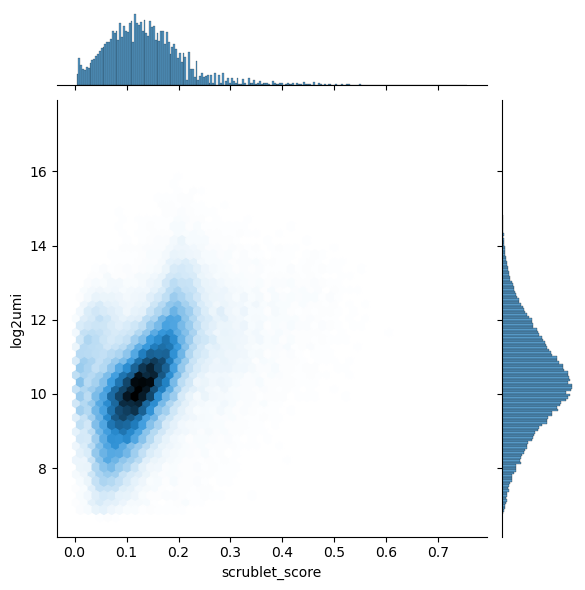

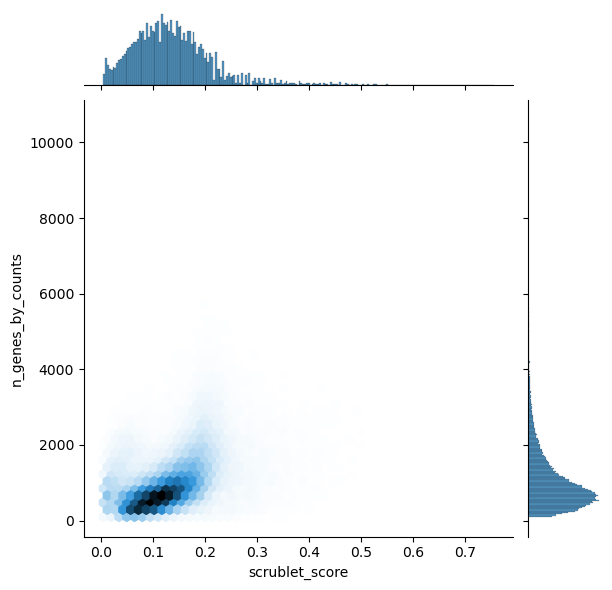

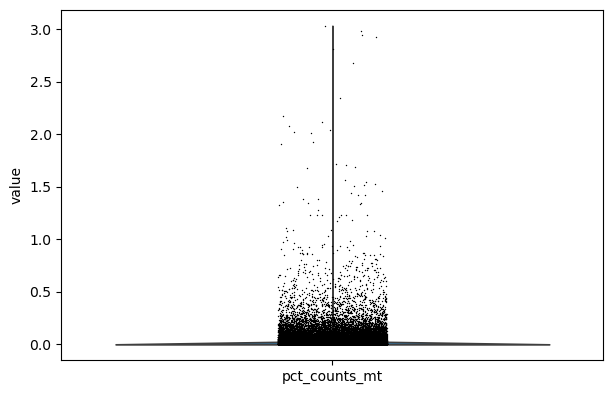

In [25]:
#Check mt%, %intronic, scurblet score and log2umi distribution for the raw dataset
adata.var['mt'] = adata.var['chr'] == 'MT'
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
adata.obs['%intronic']=adata.obs['n_intronic_umi']/adata.obs['n_umi']
adata.obs['log2umi']=[math.log2(i) for i in adata.obs['n_umi']]
#Visualize distributions
df=adata.obs
sns.jointplot(data=df,y='log2umi',x='%intronic',kind='hex')
sns.jointplot(data=df,y='log2umi',x='scrublet_score',kind='hex')
sns.jointplot(data=df,y='n_genes_by_counts',x='scrublet_score',kind='hex')
sc.pl.violin(adata, ['pct_counts_mt'],jitter=0.1)   

In [29]:
min(adata.obs['n_genes_by_counts'])
min(adata.obs['%intronic'])

0.20095693779904306

In [9]:
#Doublet removal: cluster cells at high resolution
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[:,select_genes].copy()
adata.layers['raw'] = adata.X
bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=10000)
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
bioalpha.sc.tl.louvain(adata, resolution=6)
bioalpha.sc.tl.umap(adata,min_dist=0.25,spread=1.0, n_components=2)

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


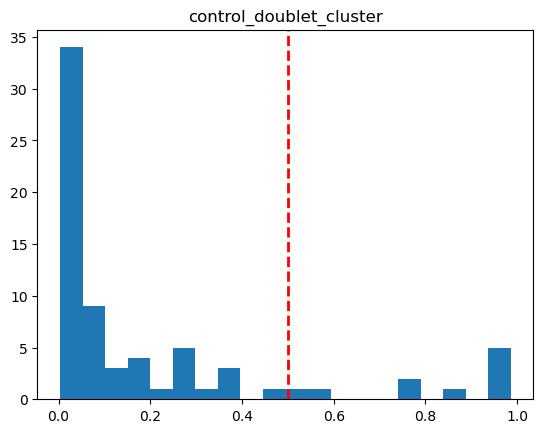

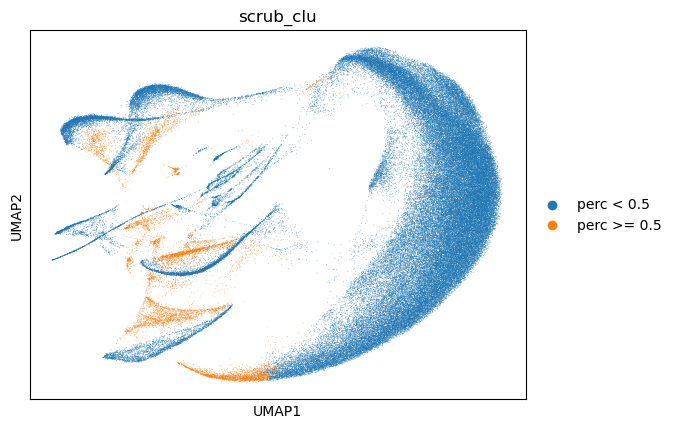

In [10]:
#Doublet removal: filter out clusters with percentage of doublet score > 0.2
df=adata.obs
thre = 0.5
def calculate_doublet_perc(s,thre):
    return (s>thre).mean()
select_clu = df.groupby('louvain')['scrublet_score_from_filtered'].apply(calculate_doublet_perc,thre=0.2)
plt.hist(select_clu,bins=20);
plt.axvline(x=thre, color='red', linestyle='dashed', linewidth=2)
plt.title(f'{region}_doublet_cluster')
select_cells = np.where(df['louvain'].isin(select_clu[select_clu<thre].index)) 
adata.obs[f'scrub_clu'] = f'perc >= {thre}'
adata.obs.loc[adata.obs.index[select_cells],'scrub_clu']= f'perc < {thre}'
doublets = sum(adata.obs['scrub_clu']==f'perc >= {thre}')
#print(f'Filtering out {doublets} doublets {doublets/adata_raw*100}%.')
sc.pl.umap(adata,color='scrub_clu')

In [37]:
#save intermediate file for tacco cell class annotation
adata.write_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)

##### Note: Use Run_tacco.py to annotate cell class and subcluster and then use the output for subsequent steps
##### 1. module load mamba/latest
##### 2. source activate TACCO_env
##### 3. open ./Run_tacco_v2.py and change the region param to capitalized region name
##### 4. python ./Run_tacco_v2.py

In [6]:
#Open adata file after tacco cell class annotation
adata = sc.read_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)

In [11]:
adata = adata[adata.obs['scrub_clu']==f'perc < {thre}']

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


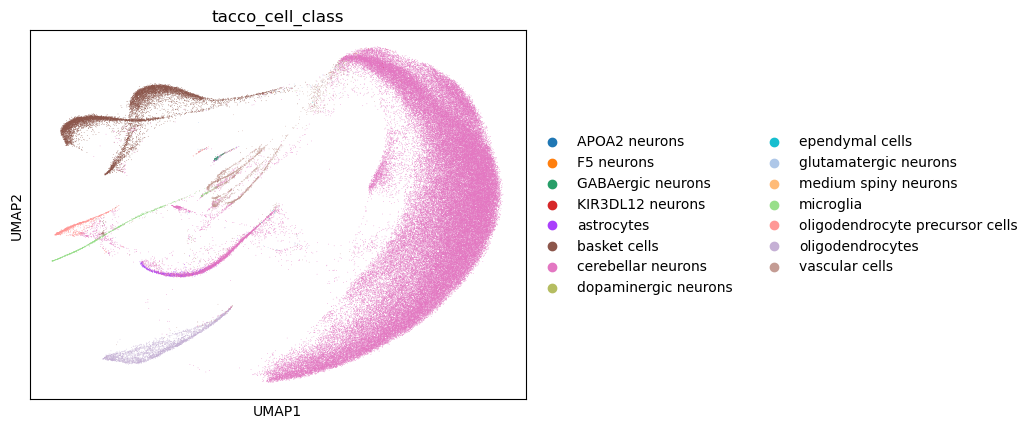

In [12]:
sc.pl.umap(adata,color='tacco_cell_class')

Non-Neuron threshold: 8.48 12.35; Neuron threshold: 9.00 12.78


Text(0.5, 1.0, 'control_neurons')

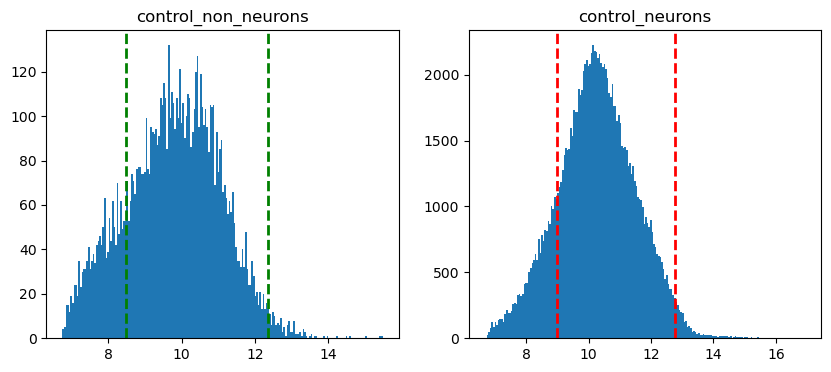

In [13]:
#filter low and high umi cells with neurons and non-neurons
neurons = ['cerebellar neurons','dopaminergic neurons','GABAergic neurons', 'glutamatergic neurons',
           'F5 neurons','APOA2 neurons','KIR3DL12 neurons','medium spiny neurons','basket cells',
          'serotonergic neurons']
non_neurons = ['astrocytes','ependymal cells','microglia','oligodendrocyte precursor cells',
               'oligodendrocytes','vascular cells','KIR3DL12 microglia']

#Calculating threshold
df_non_neurons = adata.obs[adata.obs['tacco_cell_class'].isin(non_neurons)]
df_neurons = adata.obs[adata.obs['tacco_cell_class'].isin(neurons)]
#neruon threshold
a1 = statistics.mean(df_non_neurons['log2umi'])-statistics.stdev(df_non_neurons['log2umi'])
a2 = statistics.mean(df_non_neurons['log2umi'])+2*statistics.stdev(df_non_neurons['log2umi'])
#non-neruon threshold
b1 = statistics.mean(df_neurons['log2umi'])-statistics.stdev(df_neurons['log2umi'])
b2 = statistics.mean(df_neurons['log2umi'])+2*statistics.stdev(df_neurons['log2umi'])
print('Non-Neuron threshold: %.2f %.2f; Neuron threshold: %.2f %.2f'%(a1,a2,b1,b2))

#plotting
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
ax[0].hist(df_non_neurons['log2umi'],bins=200);
ax[0].axvline(x=a1, color='green', linestyle='dashed', linewidth=2)
ax[0].axvline(x=a2, color='green', linestyle='dashed', linewidth=2)
ax[0].set_title(f'{region}_non_neurons')

ax[1].hist(df_neurons['log2umi'],bins=200,);
ax[1].axvline(x=b1, color='red', linestyle='dashed', linewidth=2)
ax[1].axvline(x=b2, color='red', linestyle='dashed', linewidth=2)
ax[1].set_title(f'{region}_neurons')

In [14]:
select_non_neurons = df_non_neurons.index[(df_non_neurons['log2umi']>a1) & (df_non_neurons['log2umi']<a2)]
select_neurons = df_neurons.index[(df_neurons['log2umi']>b1) & (df_neurons['log2umi']<b2)]
select_cells = select_neurons.union(select_non_neurons)
umi_cells = adata.shape[0]-len(select_cells)
#print(f'filter out {umi_cells}({umi_cells/adata_raw*100}%) low and high umi cells.')
adata = adata[select_cells] 
del umi_cells

In [15]:
#save metadata 
select_meta = adata.obs
select_index = select_meta.index
tacco_mat = adata.obsm['tacco_cell_class']
tacco_mat = adata.obsm['tacco_cell_subcluster']

In [17]:
#Start from raw data again and re-do dimensional reduction and clustering with the filtered cells
data_dir = f'/scratch/klchiou/bican/hdf5/raw_filtered/anndata_rna_{region}-all.h5ad'
adata_raw = sc.read_h5ad(data_dir)
adata = adata_raw[select_index]
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[:,select_genes].copy()
adata.layers['raw'] = adata.X
bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=5000) #n_top_genes=10000
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
bioalpha.sc.pp.regress_out(adata, keys='n_umi')
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
bioalpha.sc.tl.louvain(adata, resolution=6)
bioalpha.sc.tl.umap(adata,min_dist=0.25,spread=1.0, n_components=2)

In [18]:
adata.obs['tacco_cell_class']=select_meta['tacco_cell_class']
adata.obs['tacco_cell_class_score']=select_meta['tacco_cell_class_score']
adata.obs['tacco_cell_subcluster']=select_meta['tacco_cell_subcluster']
adata.obs['tacco_cell_subcluster_score']=select_meta['tacco_cell_subcluster_score']
adata.obs['log2umi']=select_meta['log2umi']
adata.obs['pct_counts_mt']=select_meta['pct_counts_mt']

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


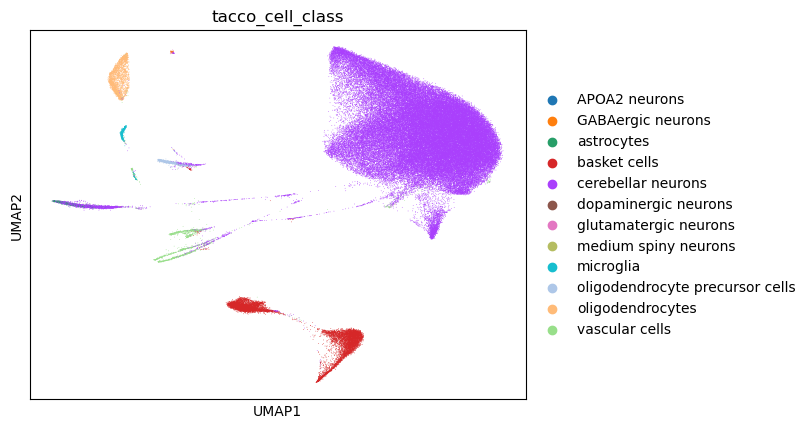

In [19]:
sc.pl.umap(adata,color='tacco_cell_class')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


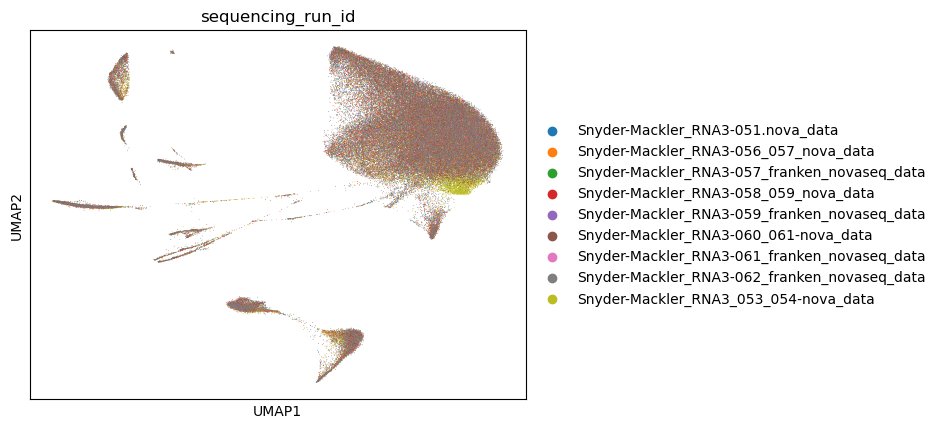

In [20]:
sc.pl.umap(adata,color='sequencing_run_id')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap

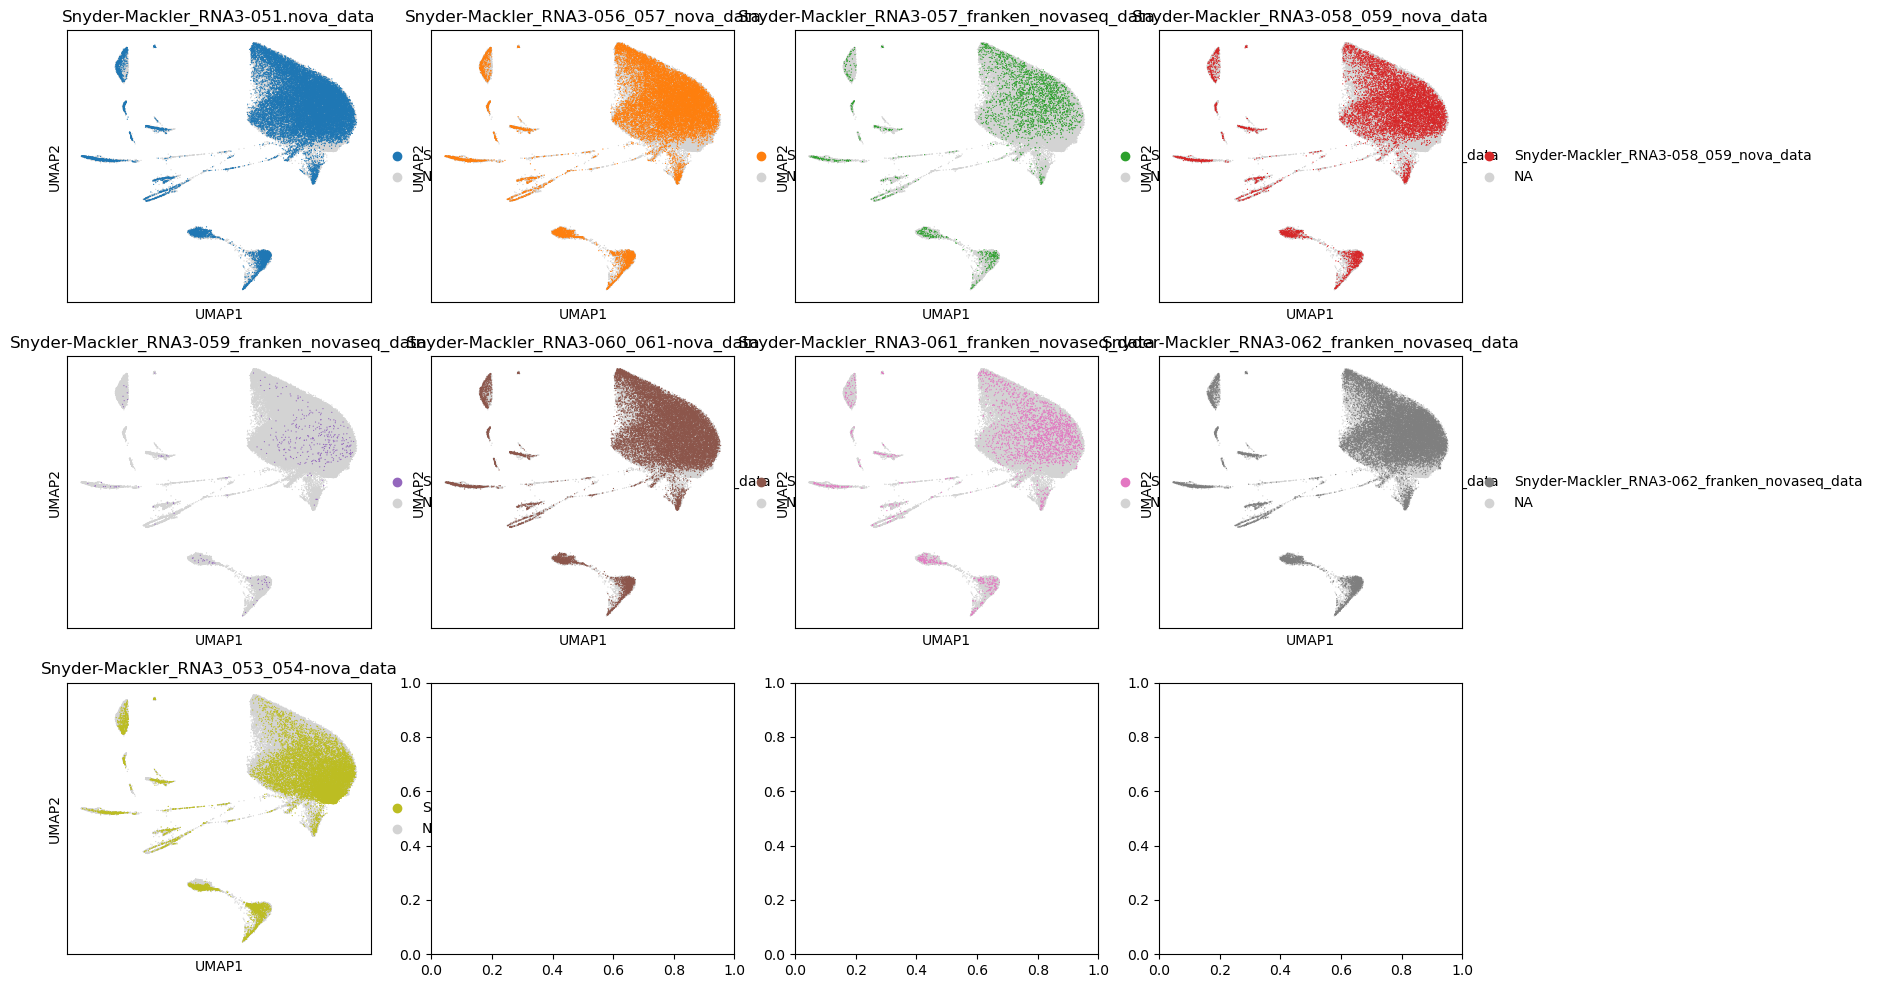

In [21]:
fig, axes = plt.subplots(figsize=(18,12),ncols=4,nrows=3)    #umap split into regions
axes = axes.reshape(3,4)
regions = adata.obs['sequencing_run_id'].cat.categories.tolist()
for i in range(3):
    for j in range(4):
        k = i*4+j
        if k <len(regions):
            sc.pl.umap(adata,color= 'sequencing_run_id',groups=regions[k],title=regions[k],show=False,ax=axes[i,j],sort_order=True,size=3)
        else: 
            break
fig.tight_layout(pad=4.0)

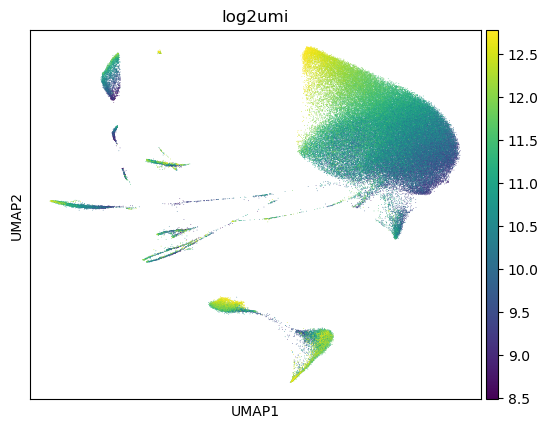

In [22]:
sc.pl.umap(adata,color='log2umi')

In [25]:
#Prepare metadata for louvain clusters
df = adata.obs.groupby('louvain')['tacco_cell_class'].value_counts(normalize=True).unstack()
first_cc = pd.concat([df.idxmax(axis=1),df.max(axis=1)],axis=1)
first_cc.columns = ['first_cc','first_cc_score']
df = adata.obs.groupby('louvain')['tacco_cell_subcluster'].value_counts(normalize=True).unstack()
first_sc = pd.concat([df.idxmax(axis=1),df.max(axis=1)],axis=1)
first_sc.columns = ['first_sc','first_sc_score']
temp_1 = adata.obs.groupby('louvain')['scrublet_score_from_filtered'].mean()
temp_2 = adata.obs.groupby('louvain')['tacco_cell_class_score'].mean()
temp_3 = adata.obs.groupby('louvain')['tacco_cell_subcluster_score'].mean()
temp_4 = df.apply(lambda row: row.nlargest(2).values[0]/(row.nlargest(2).values[1]+0.001), axis=1)
df_all = pd.concat([first_cc,temp_2,first_sc,temp_3,temp_1],axis=1)
df_all['1st/2nd identity'] = temp_4
df_all['sc_cc_match']=[re.findall(df_all.loc[x,'first_cc'],df_all.loc[x,'first_sc'])!=[] for x in df_all.index]

In [26]:
##Transfer annotation
#simple version (majority ruling)
df_all['cell_class_assignment']=df_all['first_cc'].astype('str')
df_all['cell_subcluster_assignment']=np.nan

#Majority ruling of subcluster for louvain cluster with top identity consisting > 70% of the cells or 
#if the top identity is >3x than the 2nd identity.
df_all.loc[df_all['first_sc_score']>=0.7,'cell_subcluster_assignment'] = df_all.loc[df_all['first_sc_score']>=0.7,'first_sc']
df_all.loc[df_all['1st/2nd identity']>=3,'cell_subcluster_assignment'] = df_all.loc[df_all['1st/2nd identity']>=3,'first_sc']

#Label cluster with inconsistent annotation in cell class annotation and cell sub cluster annotation as unknown.
df_all.loc[df_all['sc_cc_match']==False,'cell_class_assignment']='unknown-class'
df_all.loc[df_all['sc_cc_match']==False,'cell_subcluster_assignment']='unknown-subcluster'

#For all the other clusters, we label them doublet if it’s of high scrublet score or label them as unknown.
remain_cells = df_all['cell_subcluster_assignment'].isna()
df_all.loc[remain_cells & (df_all['scrublet_score_from_filtered']>0.15),'cell_class_assignment']='doublet'
df_all.loc[remain_cells & (df_all['scrublet_score_from_filtered']>0.15),'cell_subcluster_assignment']='doublet'
remain_cells = df_all['cell_subcluster_assignment'].isna()
df_all.loc[remain_cells,'cell_subcluster_assignment']='unknown-subcluster'

adata.obs['cell_class_assign'] = adata.obs['louvain'].map(df_all['cell_class_assignment'])
adata.obs['cell_subcluster_assign'] = adata.obs['louvain'].map(df_all['cell_subcluster_assignment'])

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


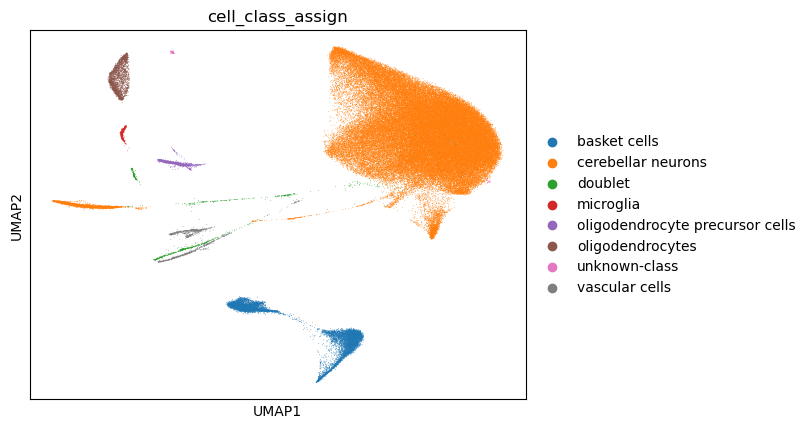

In [29]:
sc.pl.umap(adata,color='cell_class_assign')

In [4]:
#adata.write_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)
adata = sc.read_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)

In [6]:
adata.obs['UMAP_1'] = adata.obsm['X_umap'][:,0]
adata.obs['UMAP_2'] = adata.obsm['X_umap'][:,1]

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


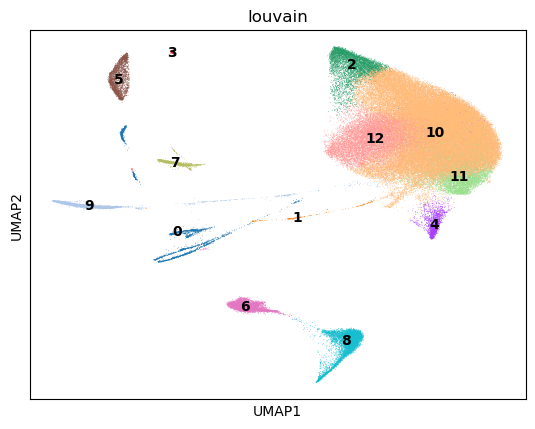

In [5]:
bioalpha.sc.tl.louvain(adata, resolution=0.3)
sc.pl.umap(adata,color='louvain',legend_loc='on data')

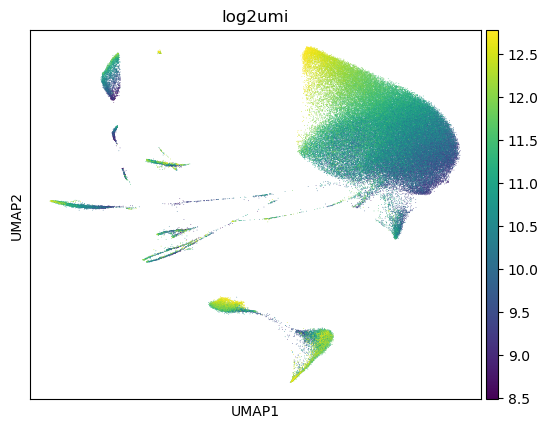

In [70]:
sc.pl.umap(adata,color='log2umi')

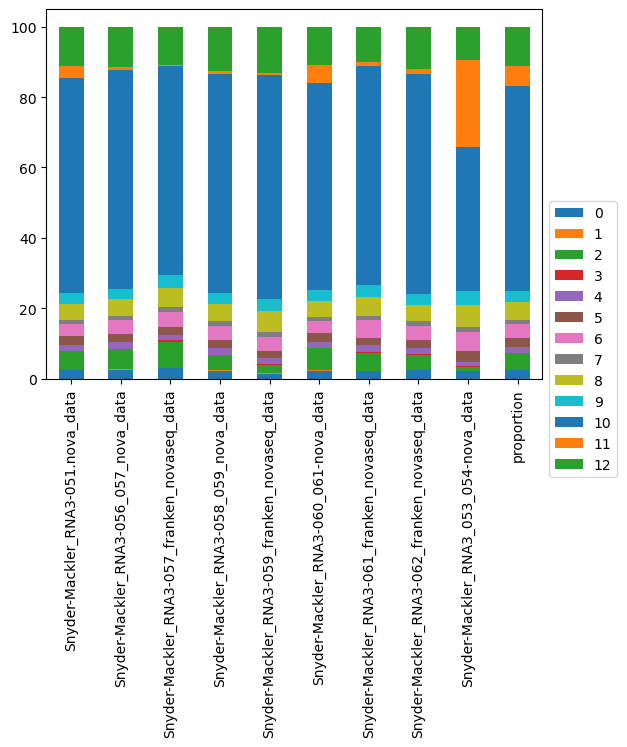

In [68]:
#barplot of sequencing_run composition in each cluster
df = adata.obs.groupby('sequencing_run_id')['louvain'].value_counts(normalize=True).unstack()
df = pd.concat([df,pd.DataFrame(adata.obs['louvain'].value_counts(normalize=True)).T])
df = df*100
df.plot.bar(stacked=True)
#plt.xticks(rotation=30)
plt.legend(bbox_to_anchor=(1, 0.5),loc = 'upper left')

In [17]:
# #Start from the raw data with all the genes
# adata_all = sc.read_h5ad("/scratch/wyang114/processed_data/anndata_rna_%s_processed.h5ad"%region)
# cell_class = 'oligodendrocytes'   #Choose the cell class here
# cell_class_obs = adata_all.obs[adata_all.obs['cell_class_assign']==cell_class]
# cell_class_index = cell_class_obs.index
# sc.pl.umap(adata_all[cell_class_index],color='cell_subcluster_assign')
# #Open the raw data with all genes
# data_dir = f'/scratch/klchiou/bican/hdf5/raw/anndata_rna_{region}-all.h5ad'
# adata = sc.read_h5ad(data_dir)

In [ ]:
#Open the raw data with all genes
data_dir = f'/scratch/klchiou/bican/hdf5/raw/anndata_rna_{region}-all.h5ad'
adata = sc.read_h5ad(data_dir)

In [35]:
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[cell_class_index,select_genes].copy()
adata.layers['raw'] = adata.X
print(adata.shape)
bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=2000)
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
bioalpha.sc.pp.regress_out(adata, keys='n_umi')  #optional
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30) #n_neighbors=30, n_pcs=30
bioalpha.sc.tl.umap(adata,min_dist=0.25,spread=1.0, n_components=2) #min_dist=0.25,spread=1.0

(91281, 2000)


In [36]:
#Transfer meta data information to the sub-clustering data
print(sum(adata.obs.index == cell_class_obs.index)/adata.shape[0])
adata.obs['cell_class_assign'] = cell_class_obs['cell_class_assign'].astype('str')
adata.obs['cell_subcluster_assign'] = cell_class_obs['cell_subcluster_assign'].astype('str')
adata.obs['log2umi'] = cell_class_obs['log2umi']
adata.obs['lv1_louvain_6'] = cell_class_obs['louvain'].astype('str')

1.0


/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


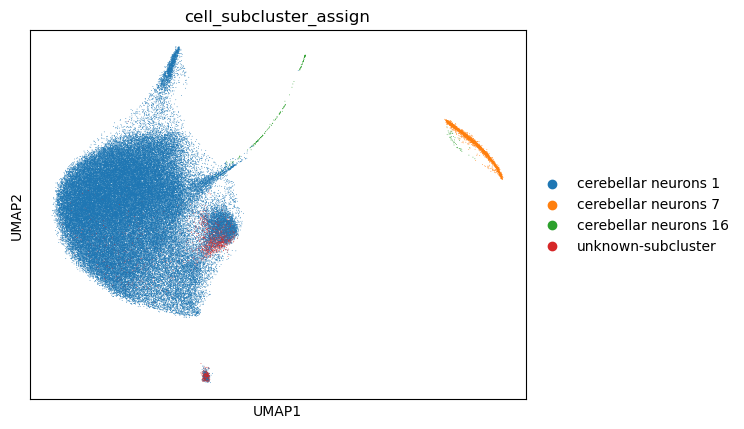

In [37]:
sc.pl.umap(adata,color='cell_subcluster_assign')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


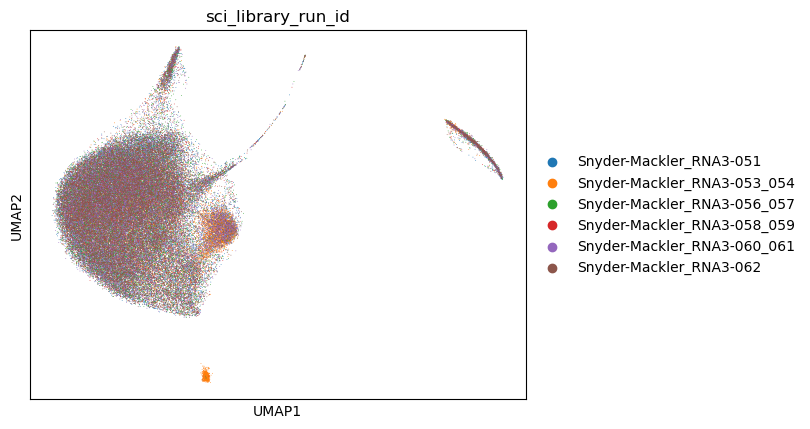

In [38]:
sc.pl.umap(adata,color='sci_library_run_id')

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap

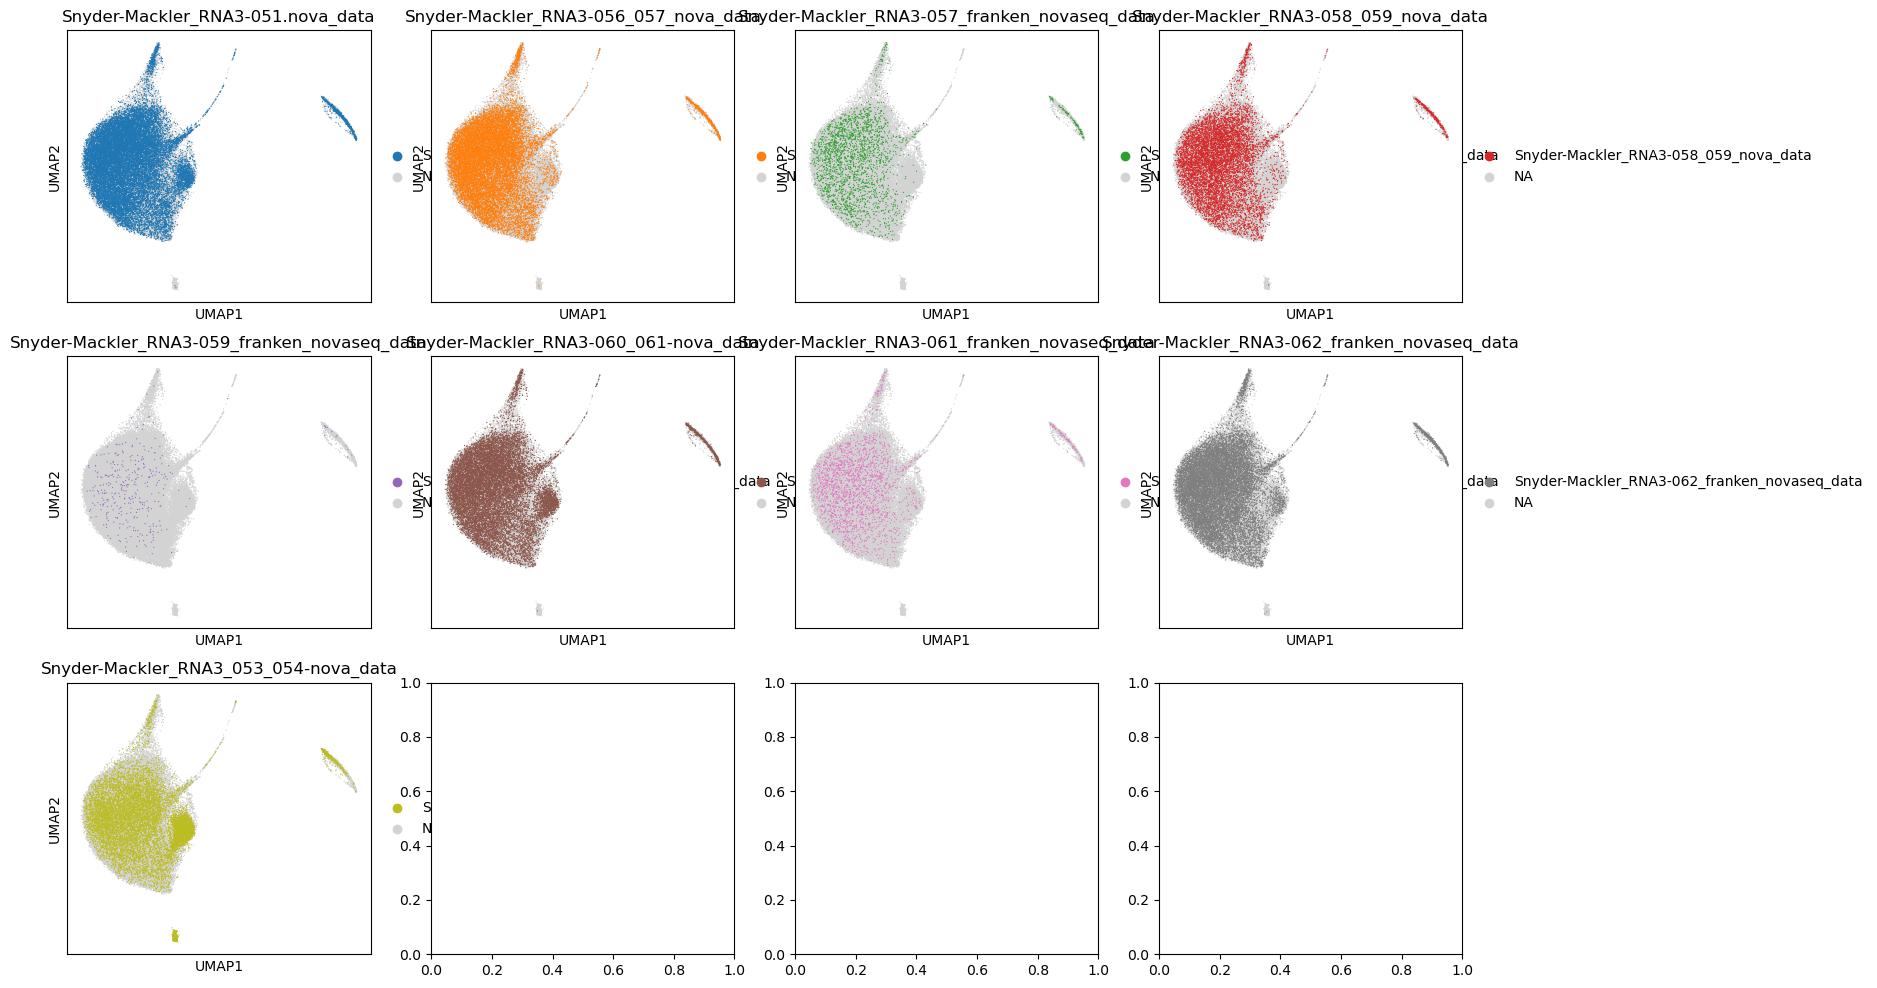

In [39]:
fig, axes = plt.subplots(figsize=(18,12),ncols=4,nrows=3)    #umap split into regions
axes = axes.reshape(3,4)
regions = adata.obs['sequencing_run_id'].cat.categories.tolist()
for i in range(3):
    for j in range(4):
        k = i*4+j
        if k <len(regions):
            sc.pl.umap(adata,color= 'sequencing_run_id',groups=regions[k],title=regions[k],show=False,ax=axes[i,j],sort_order=True,size=3)
        else: 
            break
fig.tight_layout(pad=4.0)

In [46]:
acc = sc.read_h5ad('/scratch/klchiou/bican/hdf5/raw_filtered/anndata_rna_acc-all.h5ad')

In [41]:
cn.obs['sequencing_run_id'].value_counts()

sequencing_run_id
Snyder-Mackler_RNA3-058_059_nova_data    304375
Name: count, dtype: int64

In [44]:
hip.obs['sequencing_run_id'].value_counts()

sequencing_run_id
Snyder-Mackler_RNA3_053_054-nova_data    476156
Name: count, dtype: int64

In [47]:
acc.obs['sequencing_run_id'].value_counts()

sequencing_run_id
Snyder-Mackler_RNA3_053_054-nova_data    756630
Name: count, dtype: int64